In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import numpy as np
from ultralytics import YOLO 

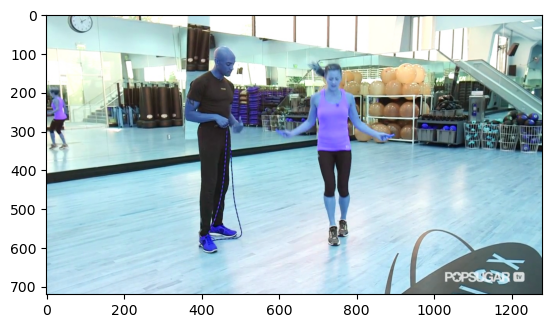

In [36]:
plt.imshow(cv2.imread("Datasets/images/000003072.jpg"))


In [26]:
def resize_with_padding(points,image, target_size=(224, 224), padding_color=(0, 0, 0)):
    h, w = image.shape[:2]
    target_w, target_h = target_size

    # Compute the scaling factor
    scale = min(target_w / w, target_h / h)
    new_w, new_h = int(w * scale), int(h * scale)

    # Resize while maintaining aspect ratio
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # Create a new blank image (padded) with the target size
    padded_image = np.full((target_h, target_w, 3), padding_color, dtype=np.uint8)
    #ajust points
    points = [(int(x * scale + (target_w - new_w) // 2), int(y * scale + (target_h - new_h) // 2)) for x, y in points]
        
    # Compute padding (center the image)
    x_offset = (target_w - new_w) // 2
    y_offset = (target_h - new_h) // 2

    # Place the resized image onto the padded canvas
    padded_image[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized

    return padded_image,points

In [27]:
def get_persons(image,points):
    yolo = YOLO("yolov8n.pt")
    results = yolo(image)
     # Get detected objects
    for result in results:
        for box in result.boxes:
            cls = int(box.cls[0].item())  # Get class ID
            if cls == 0:  # Class '0' is "person" in COCO dataset
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())  #
                #if this area contains all the points of the person
                if all([x1 <= x <= x2 and y1 <= y <= y2 for x, y in points]):
                    print("sasd")
                    #plt.imshow(cropped_image)
                    return x1, y1, x2, y2
    return []


0: 384x640 3 persons, 1 clock, 48.9ms
Speed: 1.2ms preprocess, 48.9ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
sasd
593 124 903 595


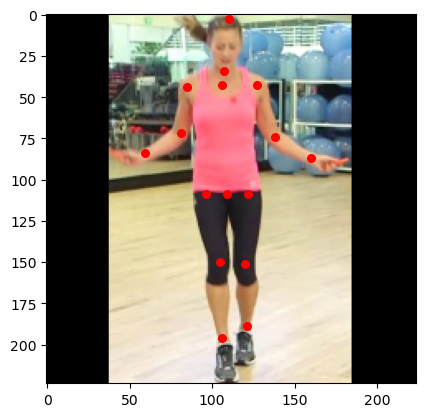

In [34]:


df = pd.read_csv('./Datasets/mpii_human_pose.csv')
df = df[df["NAME"]=="000003072.jpg"]
# Load image using OpenCV (convert BGR to RGB for Matplotlib)

keypoints = [
    ("r ankle_X", "r ankle_Y"),
    ("r knee_X", "r knee_Y"),
    ("r hip_X", "r hip_Y"),
    ("l hip_X", "l hip_Y"),
    ("l knee_X", "l knee_Y"),
    ("l ankle_X", "l ankle_Y"),
    ("pelvis_X", "pelvis_Y"),
    ("thorax_X", "thorax_Y"),
    ("upper neck_X", "upper neck_Y"),
    ("head top_X", "head top_Y"),
    ("r wrist_X", "r wrist_Y"),
    ("r elbow_X", "r elbow_Y"),
    ("r shoulder_X", "r shoulder_Y"),
    ("l shoulder_X", "l shoulder_Y"),
    ("l elbow_X", "l elbow_Y"),
    ("l wrist_X", "l wrist_Y")
]

# Select the first row (example: first image)
row = df.iloc[0]  # Change index for other images

# Convert keypoints into a list of (x, y) tuples
points = [(int(row[x]), int(row[y])) for x, y in keypoints]

# dedtect the point that is more up and more down, more left and more right
#leftmost = min(points, key=lambda p: p[0])   # Minimum x
#rightmost = max(points, key=lambda p: p[0])  # Maximum x
#topmost = min(points, key=lambda p: p[1])    # Minimum y
#bottommost = max(points, key=lambda p: p[1]) # Maximum y

image = cv2.imread("Datasets/images/000003072.jpg")
leftmost,bottommost,rightmost,topmost = get_persons(image,points)
print(leftmost,bottommost,rightmost,topmost)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# Ensure the coordinates are within the image bounds
leftmost = max(leftmost, 0)
bottommost = max(bottommost, 0)
rightmost = min(rightmost, image.shape[1])
topmost = min(topmost, image.shape[0])

# Cut image from the points
image = image[bottommost:topmost, leftmost:rightmost]

# Adjust points coordinates
points = [(x - leftmost, y - bottommost) for x, y in points]

image,points = resize_with_padding(points,image)
# Plot image
plt.imshow(image)
for (x, y) in points:
    plt.scatter(x, y, color="red", s=30)  # Red points

plt.show()